# 00 — Análise Exploratória (EDA)

Roda a EDA e gera gráficos PT/EN.

## 1. Montar o Google Drive e localizar o projeto

⚠️ **Suba o PROJETO INTEIRO para o Drive**, não só a pasta `Data`. A pasta
no Drive (por padrão `/content/drive/MyDrive/Fato_Tese_Ruido`) precisa conter:

```
Fato_Tese_Ruido/
├── requirements.txt
├── src/ftr/...        ← o módulo 'ftr' (sem isto: No module named 'ftr')
├── configs/
├── scripts/
└── Data/dataset_FINAL.json
```

A célula abaixo **localiza a pasta automaticamente** (procurando por
`src/ftr`) e mostra um checklist do que está presente/faltando.

In [1]:
import os, sys, glob

# Monta o Drive (somente no Colab).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print('Não está no Colab — usando caminho local.')


def _looks_like_project(p):
    return os.path.isdir(os.path.join(p, 'src', 'ftr'))


def _autodetect_root():
    candidates = ['/content/drive/MyDrive/Fato_Tese_Ruido']
    # procura qualquer pasta com src/ftr dentro do MyDrive (2 níveis)
    for base in ('/content/drive/MyDrive', '/content/drive/My Drive'):
        candidates += glob.glob(os.path.join(base, '**', 'src', 'ftr'), recursive=False)
        candidates += [os.path.dirname(os.path.dirname(p))
                       for p in glob.glob(os.path.join(base, '*', 'src', 'ftr'))]
    for c in candidates:
        if c and _looks_like_project(c):
            return c
    return candidates[0] if candidates else os.getcwd()


PROJECT_ROOT = _autodetect_root() if IN_COLAB else os.getcwd()
os.environ['FTR_PROJECT_ROOT'] = PROJECT_ROOT
if os.path.join(PROJECT_ROOT, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(PROJECT_ROOT, 'src'))
print('PROJECT_ROOT =', PROJECT_ROOT)

# Itens OBRIGATÓRIOS (o código + os dados).
required = {'src/ftr': 'pasta (módulo ftr)', 'configs': 'pasta',
            'scripts': 'pasta', 'Data/dataset_FINAL.json': 'dataset'}
# Itens OPCIONAIS (o Drive às vezes converte .txt/.xlsx p/ Google Docs/Sheets,
# removendo a extensão — sem problema, instalamos as deps explicitamente abaixo).
optional = {'requirements.txt': 'arquivo (opcional)'}
print('\nChecklist da pasta do projeto:')
missing = []
for rel, kind in required.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "FALTA"}] {rel}  ({kind})')
    if not ok:
        missing.append(rel)
for rel, kind in optional.items():
    ok = os.path.exists(os.path.join(PROJECT_ROOT, rel))
    print(f'  [{"OK" if ok else "--"}] {rel}  ({kind})')
if missing:
    raise SystemExit('\nFALTAM itens OBRIGATÓRIOS acima. Suba a PASTA INTEIRA do '
                     'projeto para o Drive (não só Data/).')
print('\nOK — itens obrigatórios presentes. (requirements.txt é opcional.)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT = /content/drive/MyDrive/Fato_Tese_Ruido

Checklist da pasta do projeto:
  [OK] src/ftr  (pasta (módulo ftr))
  [OK] configs  (pasta)
  [OK] scripts  (pasta)
  [OK] Data/dataset_FINAL.json  (dataset)
  [--] requirements.txt  (arquivo (opcional))

OK — itens obrigatórios presentes. (requirements.txt é opcional.)


## 2. Instalar dependências

Instala as bibliotecas explicitamente (não depende do `requirements.txt`, que o
Drive às vezes converte para Google Docs). torch já vem no Colab.

In [2]:
if IN_COLAB:
    !pip install -q 'transformers==4.48.3' 'datasets==3.3.0' 'scikit-learn==1.6.1' \
        evaluate sentencepiece sacremoses 'accelerate>=1.3.0' openpyxl seaborn pyarrow
    print('\nDependências instaladas.')
else:
    print('Local: instale com  pip install -r requirements.txt')


Dependências instaladas.


## 3. Verificar GPU, ambiente e caminhos

In [3]:
import torch
from ftr.env import describe_environment, get_paths
print('CUDA disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
import json
print(json.dumps(describe_environment(), indent=2, ensure_ascii=False))

CUDA disponível: False
{
  "in_colab": true,
  "drive_mounted": true,
  "project_root": "/content/drive/MyDrive/Fato_Tese_Ruido",
  "root_exists": true,
  "raw_dataset": "/content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json",
  "raw_dataset_exists": true,
  "python": "3.12.13",
  "platform": "linux"
}


## 4. Verificar que o dataset está no lugar

In [4]:
paths = get_paths()
print('Dataset bruto:', paths.raw_dataset)
assert paths.raw_dataset.exists(), (
    f'Dataset não encontrado em {paths.raw_dataset}. '
    'Suba Data/dataset_FINAL.json para o Drive.')
print('OK — dataset encontrado (%.1f MB).' % (paths.raw_dataset.stat().st_size/1e6))

Dataset bruto: /content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json
OK — dataset encontrado (259.0 MB).


## 5. Executar EDA
Com contagem de tokens reais (usa um tokenizer BERTimbau).

In [5]:
!cd "{PROJECT_ROOT}" && python scripts/00_eda.py --tokenizer neuralmind/bert-base-portuguese-cased --token-sample 3000

Carregando /content/drive/MyDrive/Fato_Tese_Ruido/Data/dataset_FINAL.json ...
Contando tokens com neuralmind/bert-base-portuguese-cased (amostra=3000)...
tokenizer_config.json: 100% 43.0/43.0 [00:00<00:00, 269kB/s]
config.json: 100% 647/647 [00:00<00:00, 4.09MB/s]
vocab.txt: 210kB [00:00, 46.4MB/s]
added_tokens.json: 100% 2.00/2.00 [00:00<00:00, 16.8kB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 900kB/s]
Gerando gráficos (PT/EN)...

=== RESUMO EDA ===
Classes: {'tese': 8039, 'fato': 8517, 'ruido': 8926}
Palavras: median=815 p90=3485 p99=7339 max=45786
% textos > 512 palavras: 64.5%
% textos > 512 tokens (amostra): 79.4%

Relatório: /content/drive/MyDrive/Fato_Tese_Ruido/reports/eda_report.json
Figuras:   /content/drive/MyDrive/Fato_Tese_Ruido/results/figures/eda


## 6. Visualizar os gráficos gerados

/content/drive/MyDrive/Fato_Tese_Ruido/results/figures/eda/class_distribution_pt.png


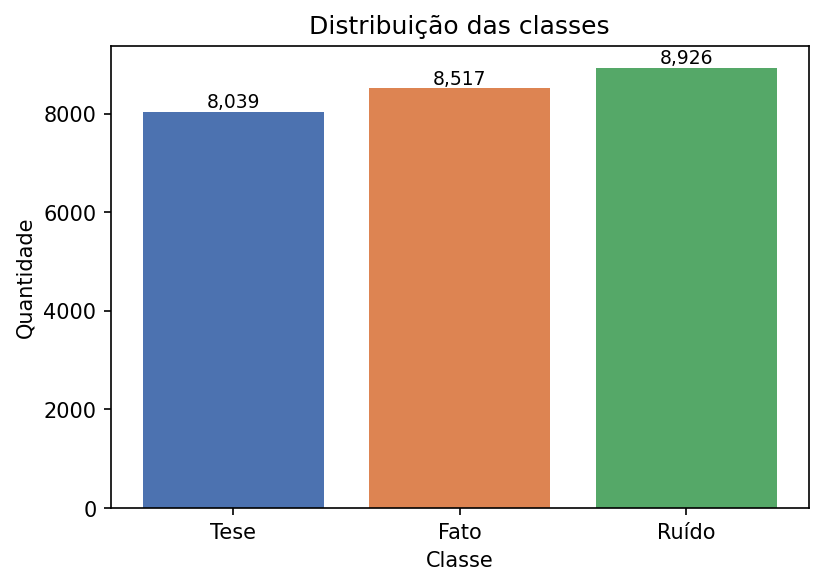

/content/drive/MyDrive/Fato_Tese_Ruido/results/figures/eda/length_distribution_tokens_pt.png


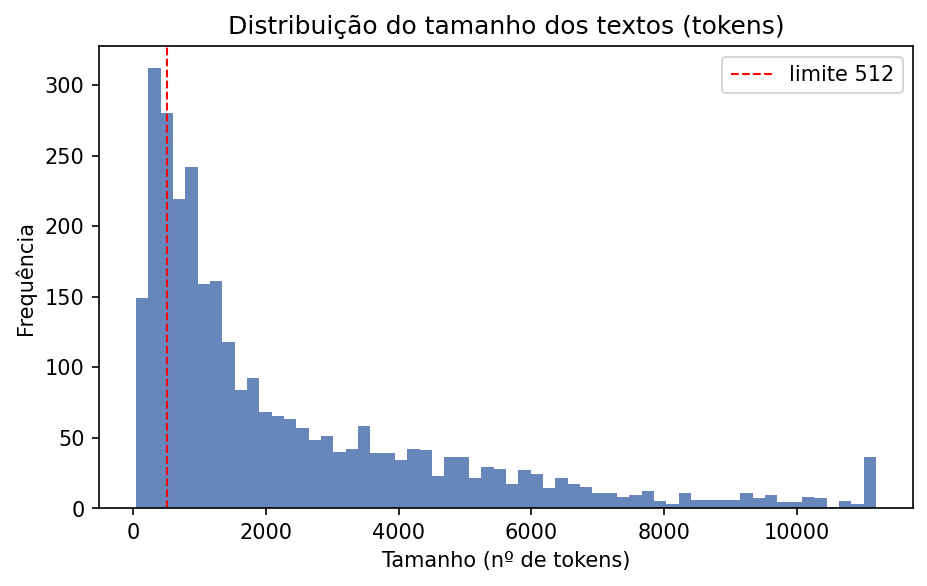

/content/drive/MyDrive/Fato_Tese_Ruido/results/figures/eda/length_distribution_words_pt.png


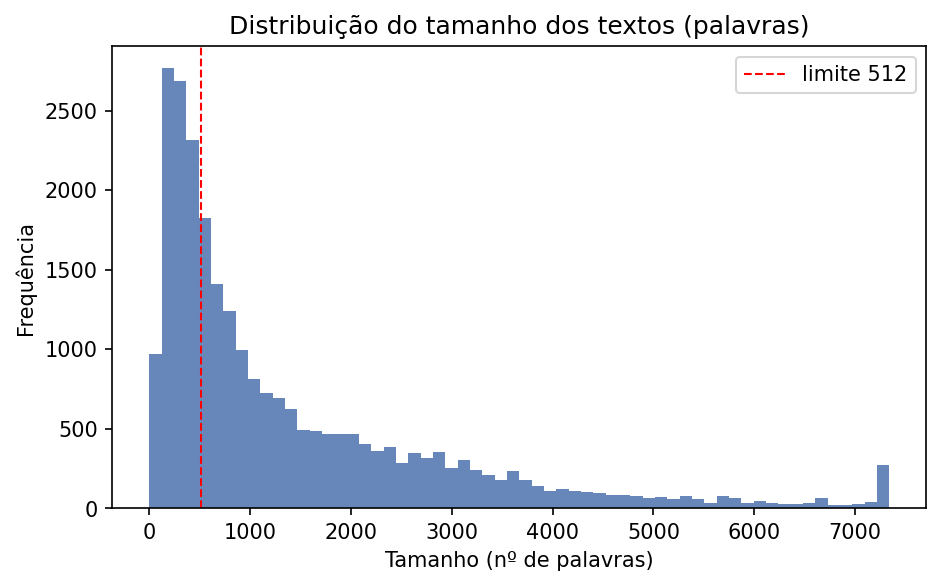

In [6]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(os.path.join(PROJECT_ROOT, 'results/figures/eda/*_pt.png'))):
    print(f); display(Image(f))